# 05 Classification models (Part B4 to B5)

Every model is scored with the **temporal expanding-window folds** chosen in Section 4. Out-of-fold (OOF) predictions cover every Train loan disbursed from 1 Sep 2022 (40,894 loans, 655 defaults). Results are shown pooled and split into the two regimes: the **2022 boom** (folds 0 to 2) and the **shifted regime from Dec 2022** (folds 3 to 4).

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_score, recall_score,
                             roc_auc_score, precision_recall_curve)
from src.config import set_seed, FIGURES, DATA_PROCESSED
from src import models as M, validation as V
from src.costs import LoanEconomics, expected_value
set_seed()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
tr = feat[feat.split == "train"].reset_index(drop=True)
econ = LoanEconomics()

## 5.1 Candidates and imbalance handling

| Model | Imbalance variants |
|---|---|
| Baseline: predict the training default rate for everyone (never flags a default) | none |
| Logistic regression | none, `class_weight="balanced"`, undersampling to 1:10 inside the fold, stronger regularisation (C = 0.1) |
| Decision tree (depth 6, leaf ≥ 100) | none, balanced |
| Random forest (300 trees, leaf ≥ 20) | none, balanced subsample |
| LightGBM (gradient boosting) | default, `scale_pos_weight = 20`, shallow (7 leaves, heavier regularisation) |

Weights and undersampling sit inside the pipeline (`src/models.py`), so they only ever touch the training fold.

In [2]:
cands = {
    "baseline": M.baseline(),
    "logreg": M.logreg(class_weight=None),
    "logreg_balanced": M.logreg(),
    "logreg_undersample": M.undersampled(M.logreg(class_weight=None)),
    "logreg_C0.1": M.logreg(class_weight=None, C=0.1),
    "tree": M.tree(),
    "tree_balanced": M.tree(class_weight="balanced"),
    "forest": M.forest(),
    "forest_balanced": M.forest(class_weight="balanced_subsample"),
    "lgbm": M.lgbm(),
    "lgbm_weighted": M.lgbm(scale_pos_weight=20),
    "lgbm_shallow": M.lgbm(num_leaves=7, n_estimators=300, min_child_samples=200, reg_lambda=5),
}
oof, folds = {}, {}
for name, model in cands.items():
    p, fid, f = V.cross_validate(model, tr, M.inputs(), V.temporal(tr))
    oof[name], folds[name] = p, f
ok = fid >= 0
fold_of = fid[ok]
y = tr.target.to_numpy()[ok]
late = fold_of >= 3
print(f"OOF loans: {ok.sum():,} ({y.sum()} defaults); boom {(~late).sum():,} loans, shifted {late.sum():,} loans")

OOF loans: 39,894 (655.0 defaults); boom 37,060 loans, shifted 2,834 loans


In [3]:
def ranking_row(name):
    f, p = folds[name], oof[name][ok]
    return {"PR-AUC": f.pr_auc.mean(), "ROC-AUC": f.roc_auc.mean(), "lift": f.pr_lift.mean(),
            "ROC boom": f.roc_auc[f.fold <= 2].mean(), "ROC shifted": f.roc_auc[f.fold >= 3].mean(),
            "lift shifted": f.pr_lift[f.fold >= 3].mean(),
            "Brier": brier_score_loss(y, p), "mean P(default)": p.mean()}
board = pd.DataFrame({n: ranking_row(n) for n in cands}).T
board.loc["(actual default rate)", "mean P(default)"] = y.mean()
board.to_csv(FIGURES.parent / "05_model_board.csv")
board.round(3).style.background_gradient(subset=["PR-AUC", "lift shifted"], cmap="Greens").format(precision=3, na_rep="")

,PR-AUC,ROC-AUC,lift,ROC boom,ROC shifted,lift shifted,Brier,mean P(default)
baseline,0.049,0.500,1.000,0.500,0.500,1.000,0.016,0.015
logreg,0.143,0.717,7.084,0.770,0.637,1.814,0.016,0.015
logreg_balanced,0.129,0.726,6.717,0.784,0.639,1.599,0.147,0.290
logreg_undersample,0.142,0.725,6.926,0.778,0.645,1.857,0.028,0.068
logreg_C0.1,0.140,0.717,7.147,0.776,0.629,1.754,0.016,0.015
tree,0.074,0.683,2.623,0.766,0.559,1.210,0.016,0.015
tree_balanced,0.075,0.684,3.174,0.781,0.539,1.115,0.153,0.257
forest,0.122,0.725,7.184,0.807,0.602,1.332,0.015,0.017
forest_balanced,0.110,0.741,5.212,0.821,0.620,1.466,0.051,0.140
lgbm,0.106,0.726,5.245,0.821,0.583,1.380,0.016,0.012


**Reading the board** (fold-averaged, temporal):
- **Unweighted logistic regression has the best PR-AUC (0.143) and the best lift in the shifted regime (1.81).** Stronger regularisation and undersampling are within noise of it.
- **Shallow LightGBM** has the best ROC (0.741) and the best boom-period ROC (0.83), but loses ground after Dec 2022. The default LightGBM and the forest overfit the 2022 boom: they are strongest early and weakest late.
- The single decision tree is clearly worst; one tree cannot use 30 weak signals.
- **Class weighting does not improve ranking** for any model family and ruins calibration: balanced logistic regression predicts an average default probability of 0.29 against an actual 0.016. Since the approval rule compares probabilities with a cost threshold (5.3), that would decline almost everyone. Undersampling distorts less but still inflates probabilities fourfold.

We carry forward **logistic regression (unweighted)** as the primary model and **shallow LightGBM** as the challenger. Section 7 tests whether the gap between them, and between each and the baseline, is real.

## 5.2 Ranking metrics for the finalists

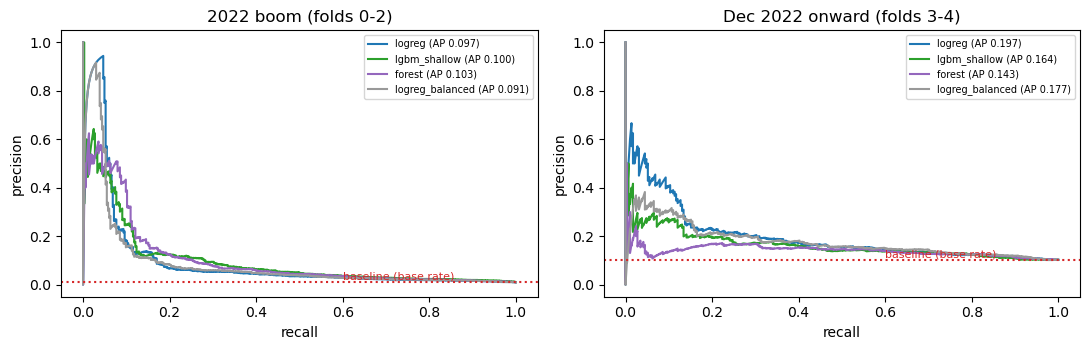

In [4]:
final = ["baseline", "logreg", "lgbm_shallow", "forest", "logreg_balanced"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for n, c in zip(final[1:], ["tab:blue", "tab:green", "tab:purple", "0.6"]):
    for ax, mask, title in [(axes[0], ~late, "2022 boom (folds 0-2)"), (axes[1], late, "Dec 2022 onward (folds 3-4)")]:
        pr, rc, _ = precision_recall_curve(y[mask], oof[n][ok][mask])
        ax.plot(rc, pr, label=f"{n} (AP {average_precision_score(y[mask], oof[n][ok][mask]):.3f})", color=c)
        ax.set(title=title, xlabel="recall", ylabel="precision")
for ax, mask in [(axes[0], ~late), (axes[1], late)]:
    ax.axhline(y[mask].mean(), ls=":", c="tab:red"); ax.text(0.6, y[mask].mean() + .01, "baseline (base rate)", color="tab:red", fontsize=8); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGURES / "05_pr_curves.png", dpi=200); plt.show()

## 5.3 Threshold sweep against the cedi cost matrix

From Section 1.5: approving a repayer earns **G = GHS 25**, approving a defaulter loses **L = GHS 380**, and declining is worth 0, so a calibrated model should decline when **P(default) > G / (G + L) = 0.062**. We sweep thresholds on the OOF predictions and value each policy in GHS per 1,000 applications, against the policy of approving everyone.

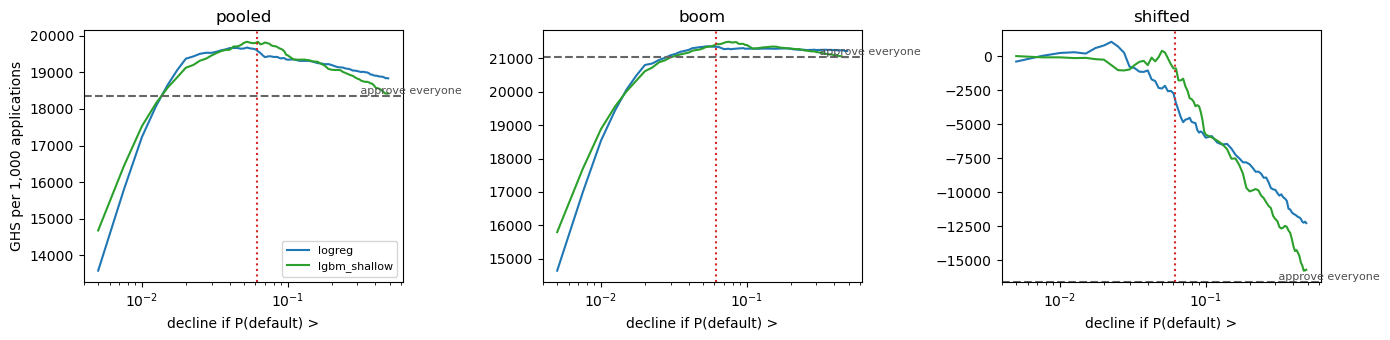

,model,regime,best_threshold,best_value,value_at_0.062,approve_all_value
0,logreg,boom,0.055,21355.640,21338.235,21022.126
1,logreg,shifted,0.022,1060.339,-3454.481,-16586.097
2,logreg,pooled,0.052,19678.774,19577.004,18350.504
3,lgbm_shallow,boom,0.075,21488.802,21421.479,21022.126
4,lgbm_shallow,shifted,0.050,396.965,-903.317,-16586.097
5,lgbm_shallow,pooled,0.052,19835.815,19835.564,18350.504


In [5]:
thr = np.round(np.concatenate([np.arange(0.005, 0.1, 0.0025), np.arange(0.1, 0.5, 0.01)]), 4)
def sweep(p, yy):
    return pd.DataFrame({"threshold": thr, "value_per_1000": [1000 * expected_value(yy, p, t, econ) / len(yy) for t in thr],
                         "approval_rate": [(p <= t).mean() for t in thr]})
sw = {(n, reg): sweep(oof[n][ok][m], y[m]) for n in ["logreg", "lgbm_shallow"] for reg, m in [("boom", ~late), ("shifted", late), ("pooled", np.ones_like(late))]}
approve_all = {reg: 1000 * expected_value(y[m], np.zeros(m.sum()), 1, econ) / m.sum() for reg, m in [("boom", ~late), ("shifted", late), ("pooled", np.ones_like(late))]}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for ax, reg in zip(axes, ["pooled", "boom", "shifted"]):
    for n, c in [("logreg", "tab:blue"), ("lgbm_shallow", "tab:green")]:
        s = sw[(n, reg)]; ax.plot(s.threshold, s.value_per_1000, label=n, color=c)
    ax.axhline(approve_all[reg], ls="--", c="0.4"); ax.text(0.3, approve_all[reg], " approve everyone", va="bottom", fontsize=8, color="0.3")
    ax.axvline(econ.threshold, ls=":", c="tab:red"); ax.set(title=reg, xscale="log", xlabel="decline if P(default) >")
axes[0].set_ylabel("GHS per 1,000 applications"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "05_threshold_value.png", dpi=200); plt.show()

best = pd.DataFrame([{"model": n, "regime": reg, "best_threshold": s.loc[s.value_per_1000.idxmax(), "threshold"],
                      "best_value": s.value_per_1000.max(),
                      "value_at_0.062": s.iloc[(s.threshold - econ.threshold).abs().argmin()].value_per_1000,
                      "approve_all_value": approve_all[reg]} for (n, reg), s in sw.items()])
best.round(3)

**Reading (GHS per 1,000 applications).**
- *Boom:* approving everyone already earns about 21,000; logistic regression at 0.062 adds only about 300 (1.5%) by declining the riskiest 1%.
- *Shifted:* approving everyone **loses about 16,600**, because one loan in ten defaults and each default costs as much as 15 good loans. Logistic regression at 0.062 cuts the loss to about 3,500, shallow LightGBM to about 900, and the best threshold found after the fact (0.022) roughly breaks even.
- *Pooled:* 18,400 for approve-all against 19,600 (logreg) and 19,800 (shallow LightGBM) at 0.062.

The model's value to NkwaPay is concentrated exactly where it is least accurate: in a high-default regime, even a weak ranking prevents large losses.

## 5.4 Calibration

The cost threshold only works if probabilities mean what they say.

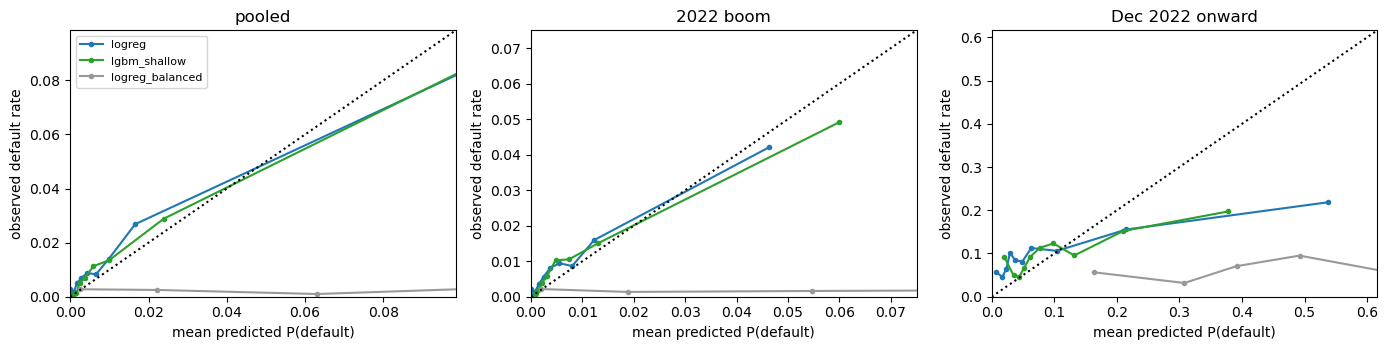

,Brier boom,Brier shifted,mean P boom,mean P shifted
baseline,0.0098,0.1002,0.0147,0.0133
logreg,0.0094,0.1017,0.0081,0.1082
lgbm_shallow,0.0093,0.0949,0.0094,0.1107
logreg_balanced,0.1249,0.4435,0.2623,0.6462
(actual),NaN,NaN,0.0098,0.1027


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (title, mask) in zip(axes, [("pooled", np.ones_like(late)), ("2022 boom", ~late), ("Dec 2022 onward", late)]):
    for n, c in [("logreg", "tab:blue"), ("lgbm_shallow", "tab:green"), ("logreg_balanced", "0.6")]:
        pt, pp = calibration_curve(y[mask], oof[n][ok][mask], n_bins=10, strategy="quantile")
        ax.plot(pp, pt, "o-", ms=3, color=c, label=n)
    lim = max(0.05, y[mask].mean() * 4)
    ax.plot([0, 1], [0, 1], ":", c="k"); ax.set(xlim=(0, lim * 1.5), ylim=(0, lim * 1.5), title=title, xlabel="mean predicted P(default)", ylabel="observed default rate")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "05_calibration.png", dpi=200); plt.show()

cal = pd.DataFrame({n: {f"Brier {r}": brier_score_loss(y[m], oof[n][ok][m]) for r, m in [("boom", ~late), ("shifted", late)]}
                    | {f"mean P {r}": oof[n][ok][m].mean() for r, m in [("boom", ~late), ("shifted", late)]}
                    for n in ["baseline", "logreg", "lgbm_shallow", "logreg_balanced"]}).T
cal.loc["(actual)", ["mean P boom", "mean P shifted"]] = [y[~late].mean(), y[late].mean()]
cal.round(4)

In the boom period both finalists sit close to the diagonal (logistic regression slightly under-predicts: mean 0.008 against 0.010 observed). From Dec 2022 the *average* is still right (0.108 predicted against 0.103 observed), because the inputs themselves shift towards riskier profiles (no history, longer terms). But the probabilities are **too spread out**: loans scored at 1 to 5% default at 5 to 10%, and loans scored above 50% default at about 22%. The Brier score there is no better than the baseline's. Weighted logistic regression is miscalibrated everywhere.

This explains 5.3: in the shifted regime the "low-risk" loans approved under a 0.062 threshold are riskier than the model says, so the value-maximising threshold drops to about 0.02.

**Remedy for deployment.** The ranking still carries some signal, so the fix is to **recalibrate on the most recent outcomes**: refit a slope and intercept on the model's log-odds (Platt scaling) using the latest resolved loans each month, and monitor observed default rates against predictions by score band. A slope below 1 is exactly the over-spread seen here. For Ghana this means the model cannot be trusted until local outcomes exist to recalibrate it (Part C).

## 5.5 Operating point

In [7]:
def at_threshold(n, t, mask):
    p, yy = oof[n][ok][mask], y[mask]
    flag = p > t
    return {"threshold": t, "decline_rate": flag.mean(), "precision": precision_score(yy, flag, zero_division=0),
            "recall": recall_score(yy, flag), "F1": f1_score(yy, flag),
            "GHS per 1,000": 1000 * expected_value(yy, p, t, econ) / mask.sum()}

rows = []
for reg, mask in [("pooled", np.ones_like(late)), ("boom", ~late), ("shifted", late)]:
    for n in ["logreg", "lgbm_shallow"]:
        rows.append({"model": n, "regime": reg, "rule": "cost threshold 0.062", **at_threshold(n, econ.threshold, mask)})
        pr, rc, th = precision_recall_curve(y[mask], oof[n][ok][mask]); f1 = 2 * pr * rc / (pr + rc + 1e-12)
        rows.append({"model": n, "regime": reg, "rule": "max-F1 threshold", **at_threshold(n, float(th[np.argmax(f1[:-1])]), mask)})
    rows.append({"model": "baseline (approve all)", "regime": reg, "rule": "-", "threshold": np.nan, "decline_rate": 0, "precision": 0,
                 "recall": 0, "F1": 0, "GHS per 1,000": approve_all[reg]})
op = pd.DataFrame(rows).set_index(["regime", "model", "rule"])
op.to_csv(FIGURES.parent / "05_operating_points.csv")
op.round(3)

threshold  decline_rate  \
regime  model                  rule                                            
pooled  logreg                 cost threshold 0.062      0.062         0.035   
                               max-F1 threshold          0.059         0.037   
        lgbm_shallow           cost threshold 0.062      0.062         0.069   
                               max-F1 threshold          0.163         0.018   
        baseline (approve all) -                           NaN         0.000   
boom    logreg                 cost threshold 0.062      0.062         0.011   
                               max-F1 threshold          0.055         0.011   
        lgbm_shallow           cost threshold 0.062      0.062         0.033   
                               max-F1 threshold          0.086         0.020   
        baseline (approve all) -                           NaN         0.000   
shifted logreg                 cost threshold 0.062      0.062         0.355   
                               max-F1 threshold          0.141         0.198   
        lgbm_shallow           cost threshold 0.062      0.062         0.545   
                               max-F1 threshold          0.144         0.223   
        baseline (approve all) -                           NaN         0.000   

                                                     precision  recall     F1  \
regime  model                  rule                                             
pooled  logreg                 cost threshold 0.062      0.148   0.316  0.202   
                               max-F1 threshold          0.148   0.331  0.205   
        lgbm_shallow           cost threshold 0.062      0.115   0.481  0.185   
                               max-F1 threshold          0.193   0.209  0.201   
        baseline (approve all) -                         0.000   0.000  0.000   
boom    logreg                 cost threshold 0.062      0.137   0.148  0.143   
                               max-F1 threshold          0.132   0.154  0.142   
        lgbm_shallow           cost threshold 0.062      0.091   0.302  0.140   
                               max-F1 threshold          0.117   0.234  0.156   
        baseline (approve all) -                         0.000   0.000  0.000   
shifted logreg                 cost threshold 0.062      0.152   0.526  0.236   
                               max-F1 threshold          0.187   0.361  0.246   
        lgbm_shallow           cost threshold 0.062      0.133   0.704  0.223   
                               max-F1 threshold          0.169   0.368  0.232   
        baseline (approve all) -                         0.000   0.000  0.000   

                                                     GHS per 1,000  
regime  model                  rule                                 
pooled  logreg                 cost threshold 0.062      19575.876  
                               max-F1 threshold          19636.662  
        lgbm_shallow           cost threshold 0.062      19824.410  
                               max-F1 threshold          19297.012  
        baseline (approve all) -                         18350.504  
boom    logreg                 cost threshold 0.062      21347.140  
                               max-F1 threshold          21348.084  
        lgbm_shallow           cost threshold 0.062      21410.685  
                               max-F1 threshold          21461.279  
        baseline (approve all) -                         21022.126  
shifted logreg                 cost threshold 0.062      -3586.803  
                               max-F1 threshold          -6538.462  
        lgbm_shallow           cost threshold 0.062       -919.195  
                               max-F1 threshold          -6870.148  
        baseline (approve all) -                        -16586.097

**Chosen operating point: logistic regression, decline when P(default) > 0.062**, the threshold derived from the cost matrix rather than tuned on these folds.

*Why this model.* It has the best PR-AUC (0.143) and the best ranking after the regime shift (ROC 0.637, lift 1.81, against 0.608 and 1.51 for shallow LightGBM). It is calibrated in the boom regime, so the cost-derived threshold means what it says, and its coefficients map directly to reason codes (Section 9) and the Model Card (Part D).

*What we give up.* Shallow LightGBM earns slightly more in cedis: about 260 more per 1,000 applications pooled (1.3%), and more in the shifted regime, mainly because it declines more borrowers there (55% against 36%). That gap is small next to fold-to-fold variation; Section 7 checks whether either difference is real.

*Why this threshold.* It follows from the cedi economics (5.3), so it moves automatically if NkwaPay's fee, recovery or funding assumptions change (`src/costs.py`). The max-F1 threshold treats a missed default and a wrongly declined borrower as equally bad, which the cost matrix says they are not: a default costs 15 times the profit from a good loan.

*What it means in practice.* In the boom regime it declines about 1% of applicants and catches 15% of defaults with 14% precision. In the shifted regime it declines 36% and catches 53% of defaults with 15% precision. Pooled F1 is 0.20; the max-F1 threshold happens to sit at 0.059, almost the same point. Because shifted-regime probabilities are over-spread, the threshold should be applied **after recalibration** on recent outcomes; without it NkwaPay approves loans that are riskier than their scores say.

In [8]:
pd.DataFrame({n: oof[n] for n in ["logreg", "lgbm_shallow", "baseline"]}).assign(
    tbl_loan_id=tr.tbl_loan_id, target=tr.target, fold=fid).to_pickle(DATA_PROCESSED / "oof_classification.pkl")